In [1]:

#  Moving-Average Trading Strategy Backtester

!pip -q install yfinance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Download historical SPY market data

ticker = "SPY"

data = yf.download(
    ticker,
    start="2020-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)

# Keep adjusted closing prices
prices = data["Close"].copy()

# Handle yfinance's possible multi-level columns
if isinstance(prices, pd.DataFrame):
    prices = prices.iloc[:, 0]

prices.name = "Close"

# Display first five observations
print(prices.head())

print("\nNumber of trading days:", len(prices))


Date
2020-01-02    295.391785
2020-01-03    293.154999
2020-01-06    294.273346
2020-01-07    293.446014
2020-01-08    295.009857
Name: Close, dtype: float64

Number of trading days: 1508


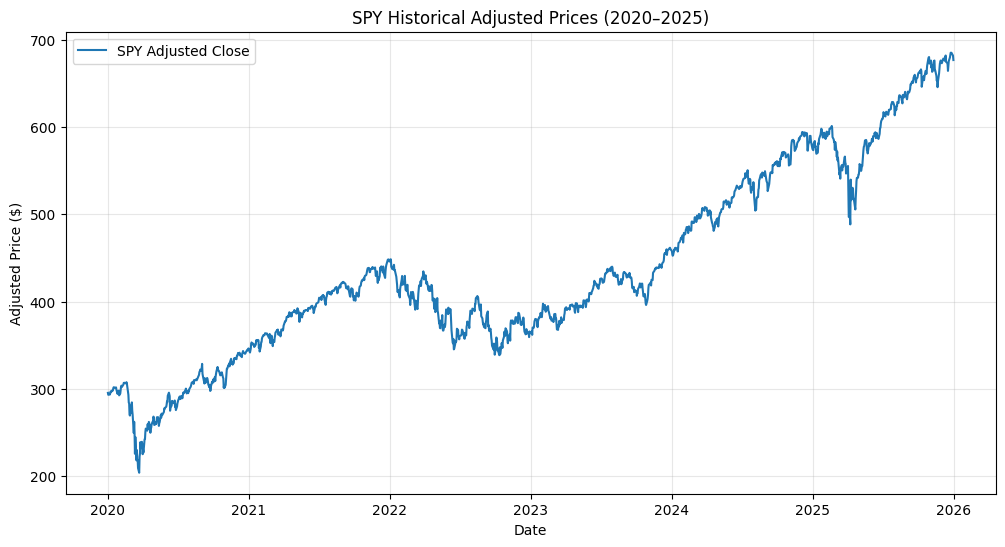

In [3]:

# Plot historical SPY prices

plt.figure(figsize=(12, 6))

plt.plot(
    prices.index,
    prices,
    label="SPY Adjusted Close"
)

plt.title("SPY Historical Adjusted Prices (2020–2025)")
plt.xlabel("Date")
plt.ylabel("Adjusted Price ($)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [4]:

# Calculate moving averages

short_window = 20
long_window = 50

ma20 = prices.rolling(window=short_window).mean()
ma50 = prices.rolling(window=long_window).mean()

# Combine into one DataFrame
strategy_data = pd.DataFrame({
    "Close": prices,
    "MA20": ma20,
    "MA50": ma50
})

print(strategy_data.tail(10))


                 Close        MA20        MA50
Date                                          
2025-12-17  664.233826  670.414627  667.630559
2025-12-18  669.249695  671.099243  667.697042
2025-12-19  675.315369  672.586749  667.923422
2025-12-22  679.522461  673.963080  668.592871
2025-12-23  682.628235  675.014877  669.126176
2025-12-24  685.029480  675.875595  669.723531
2025-12-26  684.960022  676.502325  670.261326
2025-12-29  682.519043  676.823483  670.839933
2025-12-30  681.685547  677.257303  671.327671
2025-12-31  676.635010  677.376270  671.577673


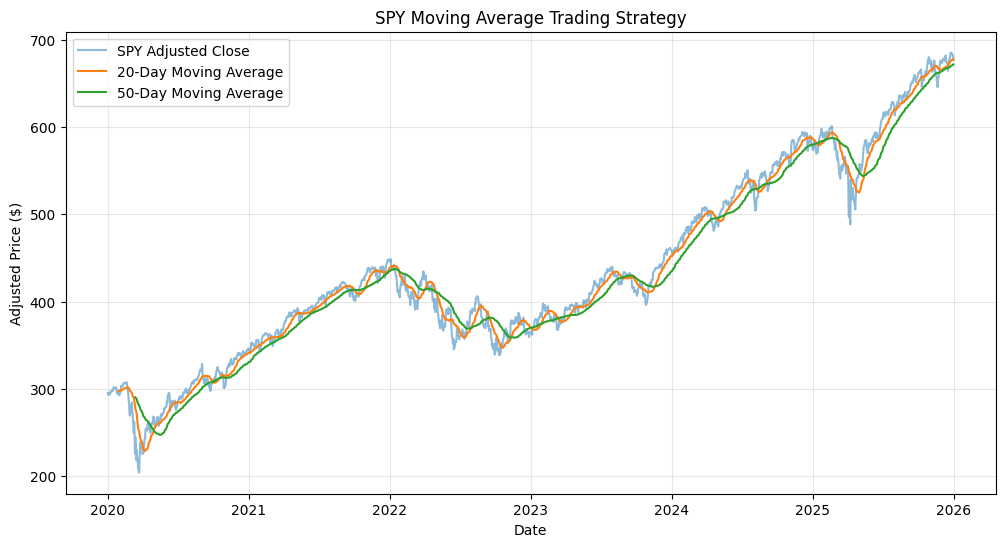

In [5]:

plt.figure(figsize=(12, 6))

plt.plot(
    strategy_data.index,
    strategy_data["Close"],
    label="SPY Adjusted Close",
    alpha=0.5
)

plt.plot(
    strategy_data.index,
    strategy_data["MA20"],
    label="20-Day Moving Average"
)

plt.plot(
    strategy_data.index,
    strategy_data["MA50"],
    label="50-Day Moving Average"
)

plt.title("SPY Moving Average Trading Strategy")
plt.xlabel("Date")
plt.ylabel("Adjusted Price ($)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [6]:

# Step 6: Generate moving-average trading signals

# Start with no position
strategy_data["Signal"] = 0

# Signal = 1 when the short moving average is higher
strategy_data.loc[
    strategy_data["MA20"] > strategy_data["MA50"],
    "Signal"
] = 1

# Calculate changes in the signal
strategy_data["Trade"] = strategy_data["Signal"].diff()

# Show the most recent observations
print(strategy_data.tail(10))


                 Close        MA20        MA50  Signal  Trade
Date                                                         
2025-12-17  664.233826  670.414627  667.630559       1    0.0
2025-12-18  669.249695  671.099243  667.697042       1    0.0
2025-12-19  675.315369  672.586749  667.923422       1    0.0
2025-12-22  679.522461  673.963080  668.592871       1    0.0
2025-12-23  682.628235  675.014877  669.126176       1    0.0
2025-12-24  685.029480  675.875595  669.723531       1    0.0
2025-12-26  684.960022  676.502325  670.261326       1    0.0
2025-12-29  682.519043  676.823483  670.839933       1    0.0
2025-12-30  681.685547  677.257303  671.327671       1    0.0
2025-12-31  676.635010  677.376270  671.577673       1    0.0


In [7]:

# Step 7: Identify buy and sell signals

buy_signals = strategy_data[
    strategy_data["Trade"] == 1
]

sell_signals = strategy_data[
    strategy_data["Trade"] == -1
]

print("Number of buy signals:", len(buy_signals))
print("Number of sell signals:", len(sell_signals))

print("\nFirst 5 buy signals:")
print(buy_signals[["Close", "MA20", "MA50"]].head())

print("\nFirst 5 sell signals:")
print(sell_signals[["Close", "MA20", "MA50"]].head())


Number of buy signals: 13
Number of sell signals: 12

First 5 buy signals:
                 Close        MA20        MA50
Date                                          
2020-04-30  265.675446  253.229391  252.145605
2020-10-20  316.702911  312.845358  312.588045
2021-10-28  428.667847  415.273344  415.155133
2022-04-01  426.426086  413.454187  413.410231
2022-08-01  388.412262  370.143869  369.704738

First 5 sell signals:
                 Close        MA20        MA50
Date                                          
2020-10-01  310.855469  307.590259  308.376556
2021-10-01  406.145691  412.982445  413.606415
2022-01-25  407.788544  434.845644  435.080762
2022-05-02  390.234741  410.401221  410.714666
2022-09-16  366.072083  380.236134  381.480018


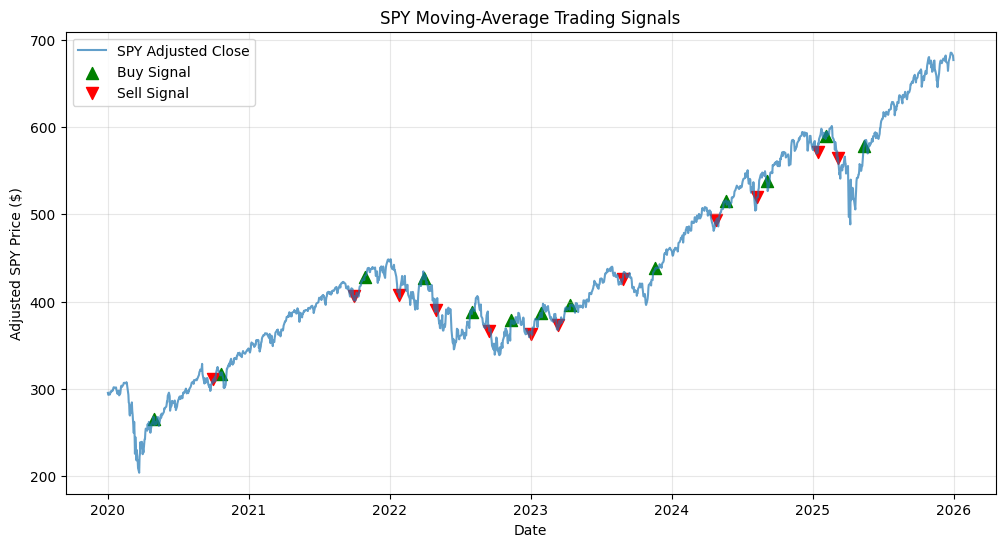

In [8]:

plt.figure(figsize=(12, 6))

plt.plot(
    strategy_data.index,
    strategy_data["Close"],
    label="SPY Adjusted Close",
    alpha=0.7
)

plt.scatter(
    buy_signals.index,
    buy_signals["Close"],
    marker="^",
    color="green",
    label="Buy Signal",
    s=75
)

plt.scatter(
    sell_signals.index,
    sell_signals["Close"],
    marker="v",
    color="red",
    label="Sell Signal",
    s=75
)

plt.title("SPY Moving-Average Trading Signals")
plt.xlabel("Date")
plt.ylabel("Adjusted SPY Price ($)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [9]:

# Step 9: Prepare strategy positions and returns

# Calculate daily SPY returns
strategy_data["Market_Return"] = (
    strategy_data["Close"].pct_change()
)

# Use the previous day's signal
strategy_data["Position"] = (
    strategy_data["Signal"].shift(1).fillna(0)
)

# Calculate strategy returns before transaction costs
strategy_data["Strategy_Return"] = (
    strategy_data["Position"]
    * strategy_data["Market_Return"]
)

# Replace the initial missing return with zero
strategy_data["Market_Return"] = (
    strategy_data["Market_Return"].fillna(0)
)

strategy_data["Strategy_Return"] = (
    strategy_data["Strategy_Return"].fillna(0)
)

print(
    strategy_data[
        ["Close", "Signal", "Position",
         "Market_Return", "Strategy_Return"]
    ].tail(10)
)


                 Close  Signal  Position  Market_Return  Strategy_Return
Date                                                                    
2025-12-17  664.233826       1       1.0      -0.011004        -0.011004
2025-12-18  669.249695       1       1.0       0.007551         0.007551
2025-12-19  675.315369       1       1.0       0.009063         0.009063
2025-12-22  679.522461       1       1.0       0.006230         0.006230
2025-12-23  682.628235       1       1.0       0.004571         0.004571
2025-12-24  685.029480       1       1.0       0.003518         0.003518
2025-12-26  684.960022       1       1.0      -0.000101        -0.000101
2025-12-29  682.519043       1       1.0      -0.003564        -0.003564
2025-12-30  681.685547       1       1.0      -0.001221        -0.001221
2025-12-31  676.635010       1       1.0      -0.007409        -0.007409


In [10]:

# Step 11: Calculate cumulative portfolio values

initial_investment = 10000

# Growth of $1 invested in each strategy
strategy_data["Market_Growth"] = (
    1 + strategy_data["Market_Return"]
).cumprod()

strategy_data["Strategy_Growth"] = (
    1 + strategy_data["Strategy_Return"]
).cumprod()

# Portfolio values starting at $10,000
strategy_data["Buy_Hold_Value"] = (
    initial_investment * strategy_data["Market_Growth"]
)

strategy_data["Strategy_Value"] = (
    initial_investment * strategy_data["Strategy_Growth"]
)

print("Final Buy-and-Hold Value: $",
      round(strategy_data["Buy_Hold_Value"].iloc[-1], 2))

print("Final Strategy Value: $",
      round(strategy_data["Strategy_Value"].iloc[-1], 2))


Final Buy-and-Hold Value: $ 22906.36
Final Strategy Value: $ 16580.39


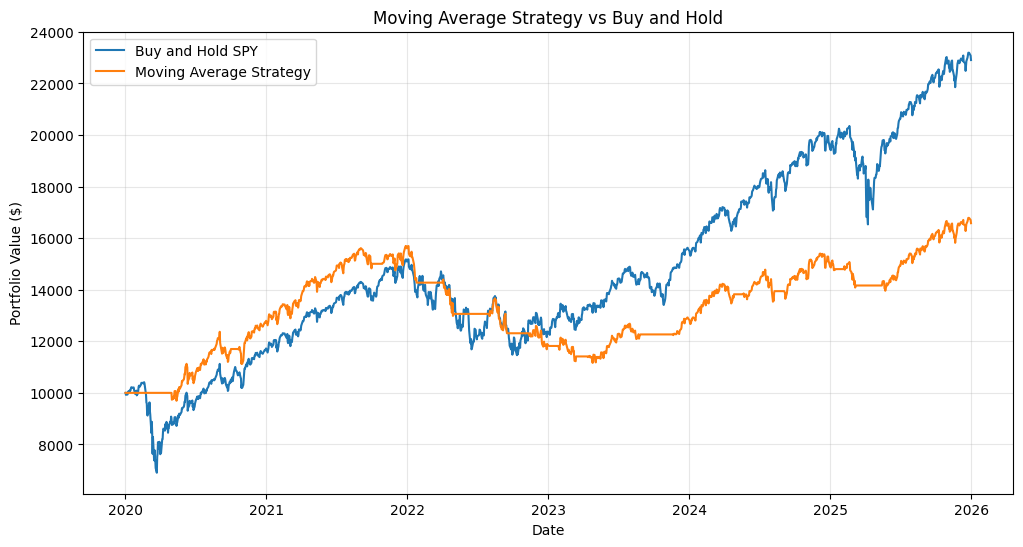

In [11]:

# Step 12: Compare portfolio performance

plt.figure(figsize=(12, 6))

plt.plot(
    strategy_data.index,
    strategy_data["Buy_Hold_Value"],
    label="Buy and Hold SPY"
)

plt.plot(
    strategy_data.index,
    strategy_data["Strategy_Value"],
    label="Moving Average Strategy"
)

plt.title("Moving Average Strategy vs Buy and Hold")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [12]:

# Step 13: Calculate total returns

buy_hold_return = (
    strategy_data["Buy_Hold_Value"].iloc[-1]
    / initial_investment - 1
) * 100

strategy_return = (
    strategy_data["Strategy_Value"].iloc[-1]
    / initial_investment - 1
) * 100

outperformance = strategy_return - buy_hold_return

print(f"Buy-and-Hold Return: {buy_hold_return:.2f}%")
print(f"Strategy Return: {strategy_return:.2f}%")
print(f"Outperformance: {outperformance:.2f} percentage points")


Buy-and-Hold Return: 129.06%
Strategy Return: 65.80%
Outperformance: -63.26 percentage points


In [13]:

# Step 15: Calculate annualized volatility

trading_days = 252

market_volatility = (
    strategy_data["Market_Return"].std()
    * np.sqrt(trading_days)
)

strategy_volatility = (
    strategy_data["Strategy_Return"].std()
    * np.sqrt(trading_days)
)

print(f"Buy-and-Hold Volatility: {market_volatility:.2%}")
print(f"Strategy Volatility: {strategy_volatility:.2%}")


Buy-and-Hold Volatility: 20.74%
Strategy Volatility: 12.25%


In [14]:

# Step 16: Calculate maximum drawdown

# Highest portfolio value reached up to each date
market_peak = strategy_data["Buy_Hold_Value"].cummax()
strategy_peak = strategy_data["Strategy_Value"].cummax()

# Percentage decline from the previous peak
strategy_data["Market_Drawdown"] = (
    strategy_data["Buy_Hold_Value"] / market_peak - 1
)

strategy_data["Strategy_Drawdown"] = (
    strategy_data["Strategy_Value"] / strategy_peak - 1
)

# Worst drawdown experienced
market_max_dd = strategy_data["Market_Drawdown"].min()
strategy_max_dd = strategy_data["Strategy_Drawdown"].min()

print(f"Buy-and-Hold Max Drawdown: {market_max_dd:.2%}")
print(f"Strategy Max Drawdown: {strategy_max_dd:.2%}")


Buy-and-Hold Max Drawdown: -33.72%
Strategy Max Drawdown: -28.89%


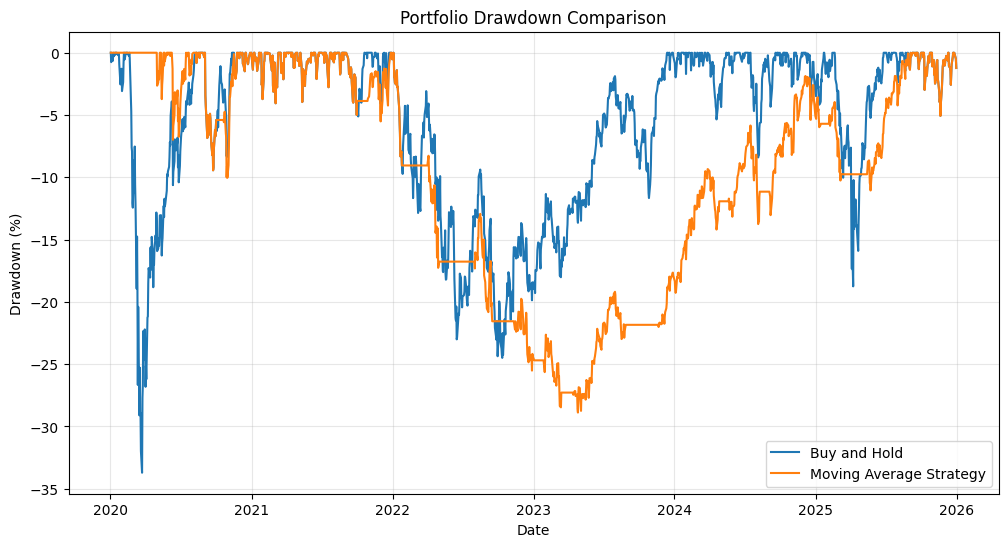

In [15]:

# Step 17: Plot portfolio drawdowns

plt.figure(figsize=(12, 6))

plt.plot(
    strategy_data.index,
    strategy_data["Market_Drawdown"] * 100,
    label="Buy and Hold"
)

plt.plot(
    strategy_data.index,
    strategy_data["Strategy_Drawdown"] * 100,
    label="Moving Average Strategy"
)

plt.title("Portfolio Drawdown Comparison")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [16]:

# Step 18: Calculate Sharpe ratios

risk_free_rate = 0.0

def calculate_sharpe(returns, annual_rf=0.0):
    daily_rf = (1 + annual_rf)**(1 / 252) - 1

    excess_returns = returns - daily_rf

    daily_std = excess_returns.std()

    if daily_std == 0:
        return np.nan

    sharpe = (
        excess_returns.mean() / daily_std
    ) * np.sqrt(252)

    return sharpe

market_sharpe = calculate_sharpe(
    strategy_data["Market_Return"],
    risk_free_rate
)

strategy_sharpe = calculate_sharpe(
    strategy_data["Strategy_Return"],
    risk_free_rate
)

print(f"Buy-and-Hold Sharpe Ratio: {market_sharpe:.3f}")
print(f"Strategy Sharpe Ratio: {strategy_sharpe:.3f}")


Buy-and-Hold Sharpe Ratio: 0.772
Strategy Sharpe Ratio: 0.751


In [17]:

# Step 19: Performance comparison table

performance = pd.DataFrame({
    "Metric": [
        "Total Return",
        "Annualized Volatility",
        "Maximum Drawdown",
        "Sharpe Ratio"
    ],
    "Buy and Hold": [
        f"{buy_hold_return:.2f}%",
        f"{market_volatility:.2%}",
        f"{market_max_dd:.2%}",
        f"{market_sharpe:.3f}"
    ],
    "Moving Average Strategy": [
        f"{strategy_return:.2f}%",
        f"{strategy_volatility:.2%}",
        f"{strategy_max_dd:.2%}",
        f"{strategy_sharpe:.3f}"
    ]
})

display(performance)


,Metric,Buy and Hold,Moving Average Strategy
0,Total Return,129.06%,65.80%
1,Annualized Volatility,20.74%,12.25%
2,Maximum Drawdown,-33.72%,-28.89%
3,Sharpe Ratio,0.772,0.751


In [18]:

# Step 21: Add transaction costs

transaction_cost = 0.0005  # 0.05% per trade

# Position is the exposure used for each day's return
# Detect changes in that exposure
strategy_data["Turnover"] = (
    strategy_data["Position"]
    .diff()
    .abs()
    .fillna(strategy_data["Position"].iloc[0])
)

# Deduct transaction costs when positions change
strategy_data["Strategy_Return_Net"] = (
    (1 + strategy_data["Strategy_Return"])
    * (1 - transaction_cost * strategy_data["Turnover"])
    - 1
)

# Recalculate portfolio value after costs
strategy_data["Strategy_Value_Net"] = (
    initial_investment
    * (1 + strategy_data["Strategy_Return_Net"]).cumprod()
)

# Total return after costs
net_return = (
    strategy_data["Strategy_Value_Net"].iloc[-1]
    / initial_investment - 1
) * 100

print(f"Strategy Return Before Costs: {strategy_return:.2f}%")
print(f"Strategy Return After Costs: {net_return:.2f}%")
print(f"Number of Trades Charged: {strategy_data['Turnover'].sum():.0f}")


Strategy Return Before Costs: 65.80%
Strategy Return After Costs: 63.74%
Number of Trades Charged: 25


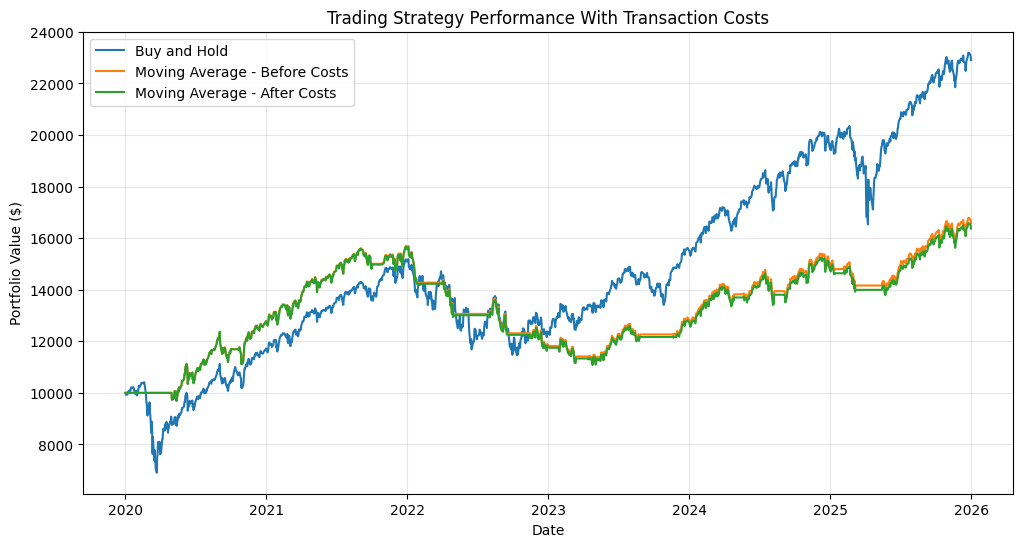

In [19]:

# Step 22: Plot performance after transaction costs

plt.figure(figsize=(12, 6))

plt.plot(
    strategy_data.index,
    strategy_data["Buy_Hold_Value"],
    label="Buy and Hold"
)

plt.plot(
    strategy_data.index,
    strategy_data["Strategy_Value"],
    label="Moving Average - Before Costs"
)

plt.plot(
    strategy_data.index,
    strategy_data["Strategy_Value_Net"],
    label="Moving Average - After Costs"
)

plt.title("Trading Strategy Performance With Transaction Costs")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [20]:

# Step 23: Backtesting validation tests

import numpy as np

# Test 1: Signals must be either 0 or 1
test1 = strategy_data["Signal"].isin([0, 1]).all()

# Test 2: Position must use the previous day's signal
expected_position = (
    strategy_data["Signal"].shift(1).fillna(0)
)

test2 = np.allclose(
    strategy_data["Position"],
    expected_position
)

# Test 3: Strategy returns must match position * market return
expected_returns = (
    strategy_data["Position"]
    * strategy_data["Market_Return"]
)

test3 = np.allclose(
    strategy_data["Strategy_Return"],
    expected_returns
)

# Test 4: Transaction costs cannot improve portfolio value
test4 = (
    strategy_data["Strategy_Value_Net"].iloc[-1]
    <= strategy_data["Strategy_Value"].iloc[-1] + 1e-8
)

# Test 5: Portfolio values must remain positive
test5 = (
    (strategy_data["Strategy_Value_Net"] > 0).all()
    and (strategy_data["Buy_Hold_Value"] > 0).all()
)

tests = {
    "Valid Trading Signals": test1,
    "No Same-Day Look-Ahead": test2,
    "Correct Strategy Returns": test3,
    "Transaction Cost Consistency": test4,
    "Positive Portfolio Values": test5
}

for name, passed in tests.items():
    print(f"{name}: {'PASSED' if passed else 'FAILED'}")

assert all(tests.values()), "One or more validation tests failed."


Valid Trading Signals: PASSED
No Same-Day Look-Ahead: PASSED
Correct Strategy Returns: PASSED
Transaction Cost Consistency: PASSED
Positive Portfolio Values: PASSED


In [21]:

# Step 24: Final performance comparison

def performance_metrics(returns, portfolio_values):
    total_return = (
        portfolio_values.iloc[-1]
        / initial_investment - 1
    ) * 100

    volatility = returns.std() * np.sqrt(252)

    drawdown = (
        portfolio_values / portfolio_values.cummax() - 1
    ).min() * 100

    sharpe = calculate_sharpe(returns, 0.0)

    return {
        "Total Return (%)": round(total_return, 2),
        "Annualized Volatility (%)": round(volatility * 100, 2),
        "Maximum Drawdown (%)": round(drawdown, 2),
        "Sharpe Ratio": round(sharpe, 3)
    }

final_results = pd.DataFrame({
    "Buy and Hold": performance_metrics(
        strategy_data["Market_Return"],
        strategy_data["Buy_Hold_Value"]
    ),
    "Strategy Before Costs": performance_metrics(
        strategy_data["Strategy_Return"],
        strategy_data["Strategy_Value"]
    ),
    "Strategy After Costs": performance_metrics(
        strategy_data["Strategy_Return_Net"],
        strategy_data["Strategy_Value_Net"]
    )
}).T

display(final_results)


,Total Return (%),Annualized Volatility (%),Maximum Drawdown (%),Sharpe Ratio
Buy and Hold,129.06,20.74,-33.72,0.772
Strategy Before Costs,65.80,12.25,-28.89,0.751
Strategy After Costs,63.74,12.25,-29.24,0.734


In [22]:

# Step 25: Evaluate a later test period

test_data = strategy_data.loc["2024-01-01":"2025-12-31"].copy()

test_market_return = (
    (1 + test_data["Market_Return"]).prod() - 1
) * 100

test_strategy_return = (
    (1 + test_data["Strategy_Return_Net"]).prod() - 1
) * 100

print("Test Period: 2024-2025")
print(f"Buy-and-Hold Return: {test_market_return:.2f}%")
print(f"Strategy After Costs: {test_strategy_return:.2f}%")
print(
    f"Difference: "
    f"{test_strategy_return - test_market_return:.2f} percentage points"
)


Test Period: 2024-2025
Buy-and-Hold Return: 47.02%
Strategy After Costs: 28.15%
Difference: -18.87 percentage points


In [23]:

# Final Project 2 Results

print("PROJECT 2: FINAL RESULTS")
print("=" * 45)

print("\nPERFORMANCE COMPARISON")
display(final_results)

print("\nVALIDATION TESTS")
for name, passed in tests.items():
    print(f"{name}: {'PASSED' if passed else 'FAILED'}")

print("\nTRADING ACTIVITY")
print("Buy signals:", len(buy_signals))
print("Sell signals:", len(sell_signals))

print("\nTRANSACTION COST IMPACT")
print(f"Before Costs: {strategy_return:.2f}%")
print(f"After Costs: {net_return:.2f}%")
print(f"Cost Impact: {strategy_return - net_return:.2f} percentage points")


PROJECT 2: FINAL RESULTS

PERFORMANCE COMPARISON


,Total Return (%),Annualized Volatility (%),Maximum Drawdown (%),Sharpe Ratio
Buy and Hold,129.06,20.74,-33.72,0.772
Strategy Before Costs,65.80,12.25,-28.89,0.751
Strategy After Costs,63.74,12.25,-29.24,0.734



VALIDATION TESTS
Valid Trading Signals: PASSED
No Same-Day Look-Ahead: PASSED
Correct Strategy Returns: PASSED
Transaction Cost Consistency: PASSED
Positive Portfolio Values: PASSED

TRADING ACTIVITY
Buy signals: 13
Sell signals: 12

TRANSACTION COST IMPACT
Before Costs: 65.80%
After Costs: 63.74%
Cost Impact: 2.06 percentage points


In [24]:

# Additional validation: no trading before enough data

early_period = strategy_data.iloc[:49]

early_signals_valid = (
    early_period["Signal"] == 0
).all()

print(
    "Moving Average Warm-Up Test:",
    "PASSED" if early_signals_valid else "FAILED"
)


Moving Average Warm-Up Test: PASSED


In [25]:

# Final validation: transaction costs

cost_test = (
    strategy_data["Strategy_Value_Net"]
    <= strategy_data["Strategy_Value"] + 1e-8
).all()

print(
    "Transaction Cost Path Test:",
    "PASSED" if cost_test else "FAILED"
)

assert cost_test


Transaction Cost Path Test: PASSED
